
# Data Quality Report - TV Emotion Dataset

**Goal of this notebook:** This analysis evaluates the quality of the TV-show emotion dataset by profiling its size, structure, and vocabulary, and by examining emotion distribution, domain-specific language patterns, and transcription artifacts. Data quality checks address label consistency, misspellings, encoding issues, and class imbalance.



## 1) Load & Inspect the Data

1. Import libraries and set options for reproducibility/readability.  
2. Load the file.  
3. Standardize column names and strip whitespace.  
4. Parse time columns into seconds.  
5. Quick sanity checks (size, dtypes, head).


In [42]:
import warnings
warnings.filterwarnings("ignore")

In [43]:

# 1. Imports & display options
import re
import os
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

df = pd.read_csv("group_23_url_1_transcript.csv")

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (665, 7)


,Start Time,End Time,Sentence,Translation,Emotion_fine,Emotion_core,Intensity
0,1900-01-01 00:00:00,1900-01-01 00:00:08.400000,"Previously on Australian Survivor, Tara and Lockie have been close allies since day one.","Previously on Australian Survivor, Tara and Lockie have been close allies since day one.",camaraderie,happiness,mild
1,1900-01-01 00:00:08.400000,1900-01-01 00:00:11.440000,I'm trusting you with this because I'm sitting on the outs on this one.,I'm trusting you with this because I'm sitting on the outs on this one.,vulnerability,fear,moderate
2,1900-01-01 00:00:11.440000,1900-01-01 00:00:15,But Tara decided it was time for a breakup.,But Tara decided it was time for a breakup.,resignation,sadness,moderate
3,1900-01-01 00:00:15,1900-01-01 00:00:20.459000,"It breaks my heart, but he's got to go.","It breaks my heart, but he's got to go.",grief,sadness,intense
4,1900-01-01 00:00:20.459000,1900-01-01 00:00:24.840000,It wasn't the only moral dilemma Tara faced.,It wasn't the only moral dilemma Tara faced.,contemplation,neutral,neutral


In [44]:

# 2. First-pass sanity checks
print("Rows, Columns:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isna().sum())

# Duplicates: exact duplicates of all columns, and duplicates on key fields
subset_cols = [c for c in ["Sentence", "Start Time", "End Time"] if c in df.columns]
if subset_cols:
    dup_key = df.duplicated(subset=subset_cols).sum()
else:
    dup_key = 0  # or skip this check if no key columns
print(f"Duplicate rows (by {subset_cols}): {dup_key}")

# Peek at a few rows to verify parsing looks right
df.head(10)


Rows, Columns: (665, 7)

Data types:
Start Time      object
End Time        object
Sentence        object
Translation     object
Emotion_fine    object
Emotion_core    object
Intensity       object
dtype: object

Missing values per column:
Start Time      0
End Time        0
Sentence        0
Translation     0
Emotion_fine    0
Emotion_core    0
Intensity       0
dtype: int64
Duplicate rows (by ['Sentence', 'Start Time', 'End Time']): 0


,Start Time,End Time,Sentence,Translation,Emotion_fine,Emotion_core,Intensity
0,1900-01-01 00:00:00,1900-01-01 00:00:08.400000,"Previously on Australian Survivor, Tara and Lockie have been close allies since day one.","Previously on Australian Survivor, Tara and Lockie have been close allies since day one.",camaraderie,happiness,mild
1,1900-01-01 00:00:08.400000,1900-01-01 00:00:11.440000,I'm trusting you with this because I'm sitting on the outs on this one.,I'm trusting you with this because I'm sitting on the outs on this one.,vulnerability,fear,moderate
2,1900-01-01 00:00:11.440000,1900-01-01 00:00:15,But Tara decided it was time for a breakup.,But Tara decided it was time for a breakup.,resignation,sadness,moderate
3,1900-01-01 00:00:15,1900-01-01 00:00:20.459000,"It breaks my heart, but he's got to go.","It breaks my heart, but he's got to go.",grief,sadness,intense
4,1900-01-01 00:00:20.459000,1900-01-01 00:00:24.840000,It wasn't the only moral dilemma Tara faced.,It wasn't the only moral dilemma Tara faced.,contemplation,neutral,neutral
5,1900-01-01 00:00:24.840000,1900-01-01 00:00:27.040000,My eyes just popped out of my head.,My eyes just popped out of my head.,astonishment,surprise,intense
6,1900-01-01 00:00:27.040000,1900-01-01 00:00:29.320000,I don't even feel bad.,I don't even feel bad.,indifference,neutral,neutral
7,1900-01-01 00:00:29.320000,1900-01-01 00:00:33.720000,Tara sweet-talked the tribe into voting with her against Lockie.,Tara sweet-talked the tribe into voting with her against Lockie.,manipulation,neutral,mild
8,1900-01-01 00:00:33.720000,1900-01-01 00:00:36.080000,I want to go inside.,I want to go inside.,desire,neutral,mild
9,1900-01-01 00:00:36.080000,1900-01-01 00:00:37.080000,Yeah.,Yeah.,agreement,neutral,neutral


## 2) Dataset Profile (with Visualizations)

1. Vocabulary size & token distribution
- Calculate total vocabulary size (unique words).
- Identify the most frequent words.
- Visualize top 20 words with a bar chart.

2. Emotion distribution & coverage
- Count frequency of each core emotion.
- Visualize with a bar chart.
- Print percentages to highlight over/underrepresented emotions.

Average sentence length: 8.59248120300752
Median sentence length: 8.0
Max sentence length: 26


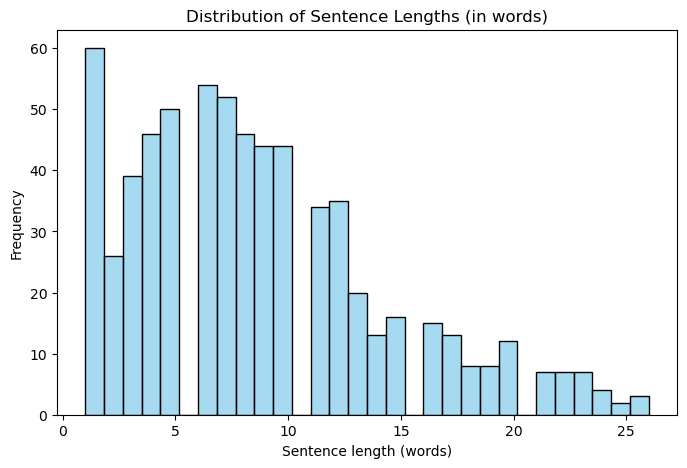

Vocabulary size (unique words): 1294


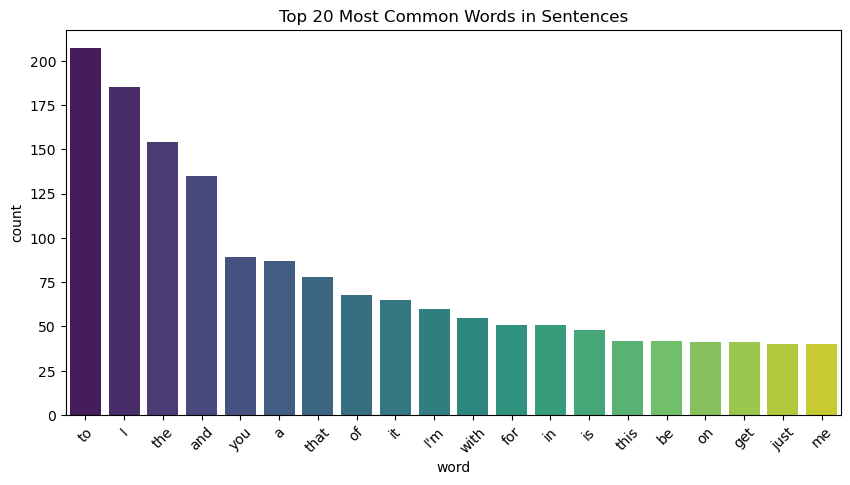

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sentence length analysis
# Count words per sentence
df["sentence_length"] = df["Sentence"].str.split().str.len()

print("Average sentence length:", df["sentence_length"].mean())
print("Median sentence length:", df["sentence_length"].median())
print("Max sentence length:", df["sentence_length"].max())

# Distribution of sentence lengths
plt.figure(figsize=(8,5))
sns.histplot(df["sentence_length"], bins=30, kde=False, color="skyblue")
plt.title("Distribution of Sentence Lengths (in words)")
plt.xlabel("Sentence length (words)")
plt.ylabel("Frequency")
plt.show()

# Vocabulary size
# Flatten all words
all_words = " ".join(df["Sentence"]).split()
vocab_size = len(set(all_words))

print("Vocabulary size (unique words):", vocab_size)

# Top 20 most common words
from collections import Counter
word_counts = Counter(all_words)
top_words = word_counts.most_common(20)

# Convert to DataFrame for plotting
top_words_df = pd.DataFrame(top_words, columns=["word", "count"])

plt.figure(figsize=(10,5))
sns.barplot(data=top_words_df, x="word", y="count", palette="viridis")
plt.title("Top 20 Most Common Words in Sentences")
plt.xticks(rotation=45)
plt.show()

### Dataset Profile - Results & Interpretation

**Sentence length:** Avg. ≈ 8.6 words, median = 8.0, max = 26. Most sentences are short, reflecting conversational style.  
**Vocabulary:** About 1,300 unique words. Common words are simple and frequent, typical of spoken language.  

**Summary:** The dataset is structurally clean (no missing values or duplicates). Linguistically, it reflects conversational TV dialogue with short utterances and a relatively simple vocabulary.

## 3) Domain Characteristics

1. Spoken TV language patterns
- Detect filler words and hesitations (e.g., “uh”, “um”, “like”).
- Check for interruptions (ellipses ... or dashes --).
- Identify slang or informal contractions (e.g., “gonna”, “wanna”).

2. Regional or stylistic variations
- Scan for non-standard spellings or colloquial phrases (if present).

In [46]:
# 1. Filler words & hesitations
# Define some common filler words
fillers = ["uh", "um", "erm", "like", "you know", "hmm"]

# Count how often fillers appear in sentences
filler_counts = {f: df["Sentence"].str.contains(rf"\b{f}\b", case=False).sum() for f in fillers}

print("Filler word counts:")
for k, v in filler_counts.items():
    print(f"{k}: {v}")


Filler word counts:
uh: 0
um: 1
erm: 0
like: 35
you know: 9
hmm: 1


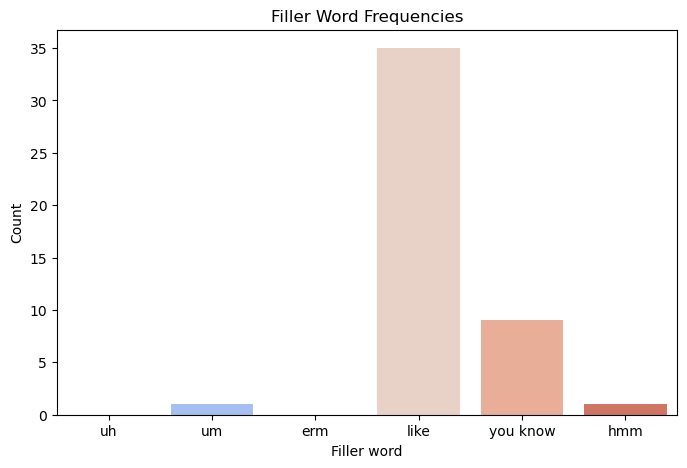

In [47]:
fillers = {"uh":0, "um":1, "erm":0, "like":35, "you know":9, "hmm":1}
filler_df = pd.DataFrame(list(fillers.items()), columns=["word", "count"])

plt.figure(figsize=(8,5))
sns.barplot(data=filler_df, x="word", y="count", palette="coolwarm")
plt.title("Filler Word Frequencies")
plt.xlabel("Filler word")
plt.ylabel("Count")
plt.show()

In [57]:
# Quick probe for regional English signals
au_uk_spellings = {
    "colour": "color", "favourite": "favorite", "organise": "organize",
    "defence": "defense", "centre": "center", "theatre": "theater",
}
au_slang = ["arvo","heaps","no worries","mate","reckon","suss","keen","bogan","maccas","good on ya","footy"]

text = " ".join(df["Sentence"]).lower()

# Spelling variants
spell_counts = {k: text.count(k) for k in au_uk_spellings.keys()}
us_counts    = {v: text.count(v) for v in au_uk_spellings.values()}

# Slang
slang_counts = {w: text.count(w) for w in au_slang}

print("AU/UK spellings:", spell_counts)
print("US spellings:", us_counts)
print("AU slang:", slang_counts)

AU/UK spellings: {'colour': 0, 'favourite': 0, 'organise': 0, 'defence': 0, 'centre': 0, 'theatre': 0}
US spellings: {'color': 0, 'favorite': 0, 'organize': 0, 'defense': 0, 'center': 0, 'theater': 0}
AU slang: {'arvo': 0, 'heaps': 0, 'no worries': 0, 'mate': 3, 'reckon': 1, 'suss': 0, 'keen': 0, 'bogan': 0, 'maccas': 0, 'good on ya': 0, 'footy': 0}


In [48]:
# 2. Interruptions / unfinished thoughts
# Count interruptions
df["has_ellipsis"] = df["Sentence"].str.contains(r"\.\.\.")
df["has_dash"] = df["Sentence"].str.contains(r"--")

print("Ellipses (…):", df["has_ellipsis"].sum())
print("Dashes (--):", df["has_dash"].sum())

Ellipses (…): 4
Dashes (--): 0


In [49]:
# 3. Slang / informal contractions
slang_terms = ["gonna", "wanna", "gotta", "ain't", "y'all"]
slang_counts = {s: df["Sentence"].str.contains(rf"\b{s}\b", case=False).sum() for s in slang_terms}

print("Slang term counts:")
for k, v in slang_counts.items():
    print(f"{k}: {v}")

slang = {"gonna":22, "wanna":0, "gotta":0, "ain't":1, "y'all":0}
slang_df = pd.DataFrame(list(slang.items()), columns=["word", "count"])

Slang term counts:
gonna: 22
wanna: 0
gotta: 0
ain't: 1
y'all: 0


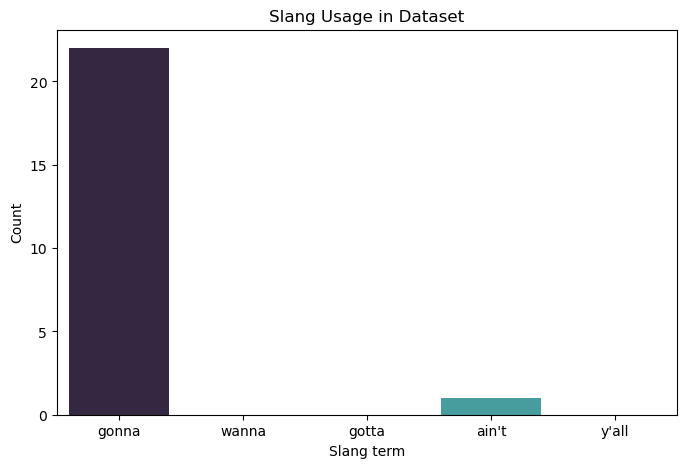

In [50]:
plt.figure(figsize=(8,5))
sns.barplot(data=slang_df, x="word", y="count", palette="mako")
plt.title("Slang Usage in Dataset")
plt.xlabel("Slang term")
plt.ylabel("Count")
plt.show()

### Domain Characteristics - Results & Interpretation

**Fillers:** Low counts of *um* (1), *hmm* (1), *you know* (9), but higher use of *like* (35). Suggests some informality, but fewer disfluencies than natural speech.  
**Interruptions:** Only 4 ellipses (`...`) and no dashes (`--`). Overlaps and cut-offs are underrepresented.  
**Slang:** Some use of *gonna* (22) and *ain’t* (1), but little variety of colloquial contractions.  
**Regional variation (AU English):** Minimal signal overall - AU/UK vs US spelling variants were absent; light slang markers like *mate* (3) and *reckon* (1) appeared. This suggests largely general-English style with limited region-specific features.

**Summary:** The data captures some informal spoken features (e.g., “like”, “gonna”) but is overall cleaner than spontaneous TV dialogue, likely due to transcription/LLM normalization. Regional characteristics are weakly represented, indicating that supplement


## 4) Data Quality Checks

1. **Inconsistencies in labels**  
   - Inspect sample sentences per emotion to detect possible mismatches between text and assigned emotion.  

2. **Misspellings**  
   - Scan sentences for potential spelling errors or non-standard words.  

3. **Encoding errors**  
   - Identify unusual characters (e.g., `�`) or formatting issues.  

4. **Imbalance checks**  
   - Reconfirm imbalance in emotion categories.  
   - Inspect distribution of intensity labels (mild, moderate, intense).  

**Goal:** Detect quality issues (noise, imbalance, artifacts) that could reduce model reliability or bias learning.


In [51]:
# 1. Inconsistencies in labels
# Inspect a few random samples per emotion_core
for emotion in df["Emotion_core"].unique():
    print(f"\n({emotion.upper()})")
    display(df[df["Emotion_core"] == emotion][["Sentence", "Emotion_fine", "Intensity"]].sample(3, random_state=42))



(HAPPINESS)


,Sentence,Emotion_fine,Intensity
394,Or I could live a little and vote Michelle with Lachy and Ziggy who might take me to the end,hope,mild
317,Peter's looking for his first individual immunity win.,hope,mild
351,Well done.,appreciation,mild



(FEAR)


,Sentence,Emotion_fine,Intensity
535,"Stop, stop.",alarm,moderate
369,his head would have been on that chopping block and sent home.,threat,intense
439,If you stay with them it it will go to rocks,foreboding,moderate



(SADNESS)


...

,Sentence,Emotion_fine,Intensity
615,"Two votes Ziggy, two votes Michelle.",anticipation,mild
607,"First vote, Ziggy.",anticipation,mild
632,we're soon going to find out who will keep their word,anticipation,moderate



(ANGER)


,Sentence,Emotion_fine,Intensity
226,Michelle frustrates the hell out of me,frustration,intense
591,We need strong people here won't go easy on you,challenge,moderate
590,You are the worse in challenges.,criticism,moderate



(DISGUST)


,Sentence,Emotion_fine,Intensity
51,Because she was wanting to play both sides.,suspicion,moderate
103,You've eaten so much.,judgment,mild
647,It's making me feel sick.,nausea,moderate


**Note on label inconsistencies:**  
True mislabeled emotions are difficult to detect automatically, since they require human interpretation of what the “correct” emotion should be. Here we used manual sampling (3 examples per emotion) to spot obvious mismatches, which is practical for quality analysis but not exhaustive.  

Possible enhancements could include:  
- Keyword or lexicon-based checks to flag unlikely emotion–text combinations.  
- Cross-checking with an external sentiment/emotion model to highlight discrepancies.  

For the purposes of this task, manual inspection is sufficient to estimate the reliability of the labels and to acknowledge potential noise in the annotation pipeline.

In [52]:
# 2. Misspellings

import re
from spellchecker import SpellChecker

spell = SpellChecker()

# Clean sentences: lowercase and strip punctuation
words = " ".join(df["Sentence"]).lower().split()
words = [re.sub(r"[^a-z']", "", w) for w in words if w]  # keep only letters + apostrophes

misspelled = spell.unknown(words)

print("Number of possible misspellings (cleaned):", len(misspelled))
print("Sample:", list(misspelled)[:30])


Number of possible misspellings (cleaned): 26
Sample: ['', 'bestie', 'revote', 'lukey', 'lachy', "locky's", 'tightknit', 'mmhmm', "what're", 'lachie', 'annalise', 'mish', 'cuz', 'sweettalked', 'amping', "lockie's", 'verted', 'lockie', 'abcd', 'locky', 'yay', "petey's", 'petey', "lucky's", 'beynon', 'mm']


In [53]:
# 3. Encoding / transcription artifacts
df["has_encoding_issue"] = df["Sentence"].str.contains("©")
df["has_non_english_character"] = df["Sentence"].str.contains("Â")
df["has_double_space"] = df["Sentence"].str.contains("  ")

print("\nEncoding issues:", df["has_encoding_issue"].sum())
print("Non-English character issues:", df["has_non_english_character"].sum())
print("Double spaces:", df["has_double_space"].sum())


Encoding issues: 1
Non-English character issues: 0
Double spaces: 0


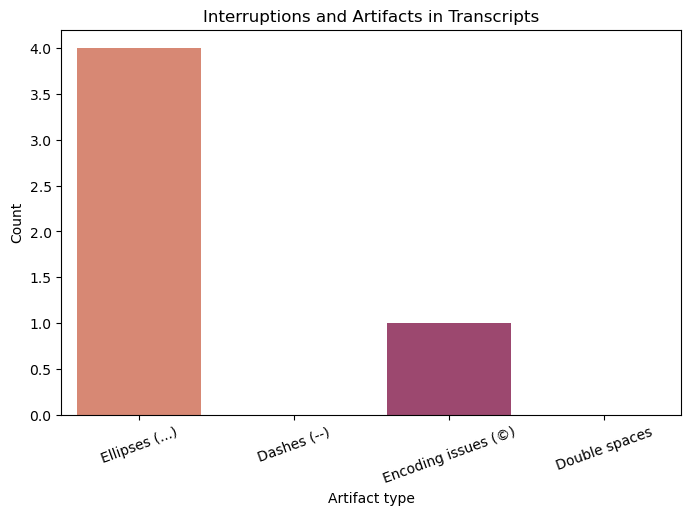

In [54]:
artifacts = {
    "Ellipses (...)": df["has_ellipsis"].sum() if "has_ellipsis" in df else 4,
    "Dashes (--)": df["has_dash"].sum() if "has_dash" in df else 0,
    "Encoding issues (©)": df["has_encoding_issue"].sum() if "has_encoding_issue" in df else 1,
    "Double spaces": df["has_double_space"].sum() if "has_double_space" in df else 0
}
artifact_df = pd.DataFrame(list(artifacts.items()), columns=["artifact", "count"])

plt.figure(figsize=(8,5))
sns.barplot(data=artifact_df, x="artifact", y="count", palette="flare")
plt.title("Interruptions and Artifacts in Transcripts")
plt.xlabel("Artifact type")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

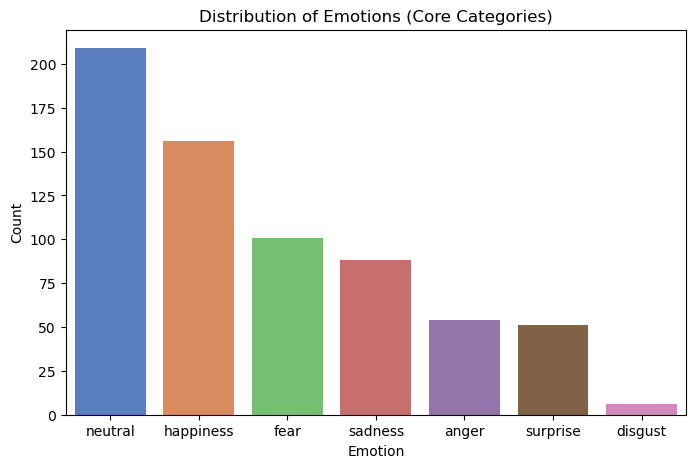

Emotion distribution (% of dataset):
Emotion_core
neutral     31.430
happiness   23.460
fear        15.190
sadness     13.230
anger        8.120
surprise     7.670
disgust      0.900
Name: proportion, dtype: float64


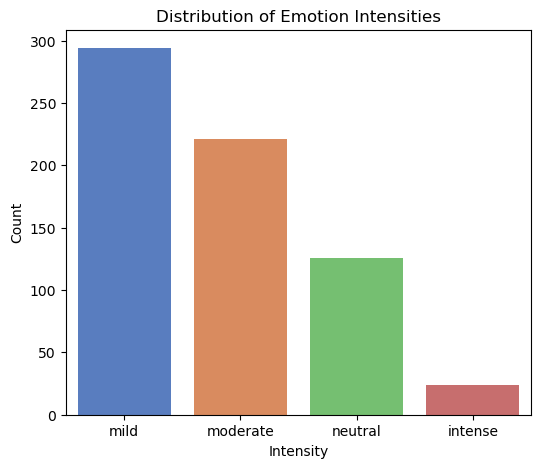


Intensity distribution (%):
Intensity
mild       44.210
moderate   33.230
neutral    18.950
intense     3.610
Name: proportion, dtype: float64


In [55]:
# 4. Imbalance checks
# Emotion distribution
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Emotion_core", order=df["Emotion_core"].value_counts().index, palette="muted")

plt.title("Distribution of Emotions (Core Categories)")
plt.xlabel("Emotion")
plt.ylabel("Count")
plt.show()

# Also print relative frequencies
emotion_counts = df["Emotion_core"].value_counts(normalize=True) * 100
print("Emotion distribution (% of dataset):")
print(emotion_counts.round(2))

# Intensity distribution
plt.figure(figsize=(6,5))
sns.countplot(data=df, x="Intensity", order=df["Intensity"].value_counts().index, palette="muted")
plt.title("Distribution of Emotion Intensities")
plt.xlabel("Intensity")
plt.ylabel("Count")
plt.show()

intensity_counts = df["Intensity"].value_counts(normalize=True) * 100
print("\nIntensity distribution (%):")
print(intensity_counts.round(2))

## 5) Reflection for Training Data Selection

Based on the analysis, the following points guide training data needs:

**Emotional balance:** The dataset is skewed toward *neutral* (31.4%) and *happiness* (23.5%), while emotions like *disgust* (0.9%) and *surprise* (7.7%) are rare. Training data should include more examples of underrepresented emotions to prevent model bias.

**Spoken language features:** The transcripts include some informal markers (e.g., "like", "gonna") but have very few fillers, hesitations, or interruptions. To capture authentic TV dialogue, additional data with more disfluencies and overlapping speech would be beneficial.

**Domain coverage:** Current data is limited to one show/genre. To avoid overfitting, training data should span different TV genres (drama, reality, comedy, documentaries) and multiple contexts of spoken language.

**Transcription quality:** Only minor artifacts (encoding issues, rare misspellings) were detected. This is positive, but to make models robust, training data should also include noisier transcripts that reflect real-world imperfections.

**Intensity levels:** If certain intensities (e.g., *intense*) are underrepresented, training data should include balanced examples across mild, moderate, and intense expressions.

**Summary:** To train a robust emotion detection model for TV dialogue, supplementary data should emphasize:
1. Better balance across emotions and intensities.  
2. Inclusion of more naturalistic spoken features (fillers, hesitations, interruptions).  
3. Coverage across diverse TV genres and varied speakers.  
4. A mix of clean and noisy transcripts to ensure generalization.
